In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

print("OpenCV version:", cv2.__version__)
image = data.camera().astype("uint8")   # to use your own image: cv2.imread("img.jpg", cv2.IMREAD_GRAYSCALE)
print("Image shape:", image.shape)

OpenCV version: 5.0.0
Image shape: (512, 512)


## 1. Keypoint detection and descriptor extraction

Number of keypoints: 791
Descriptor shape   : (791, 128)
Descriptor length  : 128


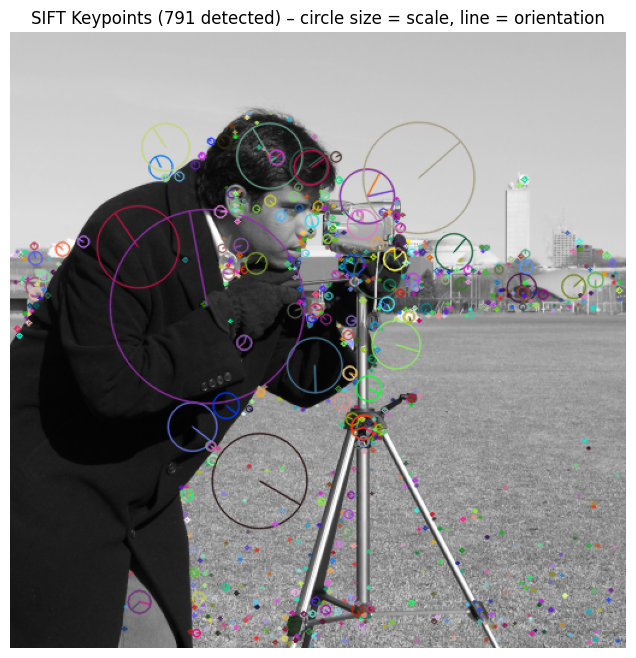

In [2]:
sift = cv2.SIFT_create()
keypoints, descriptors = sift.detectAndCompute(image, None)

output = cv2.drawKeypoints(image, keypoints, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

print("Number of keypoints:", len(keypoints))
if descriptors is not None:
    print("Descriptor shape   :", descriptors.shape)
    print("Descriptor length  :", descriptors.shape[1])

plt.figure(figsize=(10, 8))
plt.imshow(output)
plt.title(f"SIFT Keypoints ({len(keypoints)} detected) – circle size = scale, line = orientation")
plt.axis("off"); plt.show()

## 2. Keypoint properties (Task 4: 128-D descriptor check)

First keypoint -> position: (3.9, 185.4) | scale (size): 2.64 | orientation: 271.9 deg | response: 0.0267
First descriptor (first 16 of 128 values):
 [ 5.  1.  0.  1.  1.  0.  0.  0. 52.  1.  0.  0.  1.  0.  0.  0.]

All descriptors have 128 values: True
One descriptor per keypoint    : True


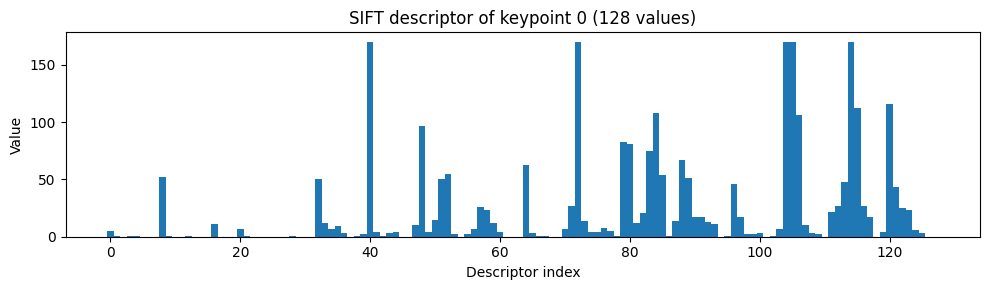

In [3]:
kp = keypoints[0]
print("First keypoint -> position:", tuple(round(v, 1) for v in kp.pt),
      "| scale (size):", round(kp.size, 2), "| orientation:", round(kp.angle, 1), "deg | response:", round(kp.response, 4))
print("First descriptor (first 16 of 128 values):\n", descriptors[0][:16])
print("\nAll descriptors have 128 values:", descriptors.shape[1] == 128)
print("One descriptor per keypoint    :", descriptors.shape[0] == len(keypoints))

plt.figure(figsize=(10, 3))
plt.bar(range(128), descriptors[0], width=1.0)
plt.title("SIFT descriptor of keypoint 0 (128 values)"); plt.xlabel("Descriptor index"); plt.ylabel("Value")
plt.tight_layout(); plt.show()

## 3. Rotation and scale (Tasks 2 and 3)
A keypoint counts as *repeated* if the same point (after applying the known transform) is found in the transformed image within 3 pixels.

Transform              kp(orig)  kp(new)  visible  repeated    rate
Original (0°)               791      791      791       791  100.0%
Rotate 30°                  791      894      736       563   76.5%
Rotate 25°                  791      872      738       541   73.3%
Scale 0.5x                  791      257      791       293   37.0%
Scale 1.5x                  791      898      459       315   68.6%
Rotate 30° + scale 0.7x      791      504      791       391   49.4%


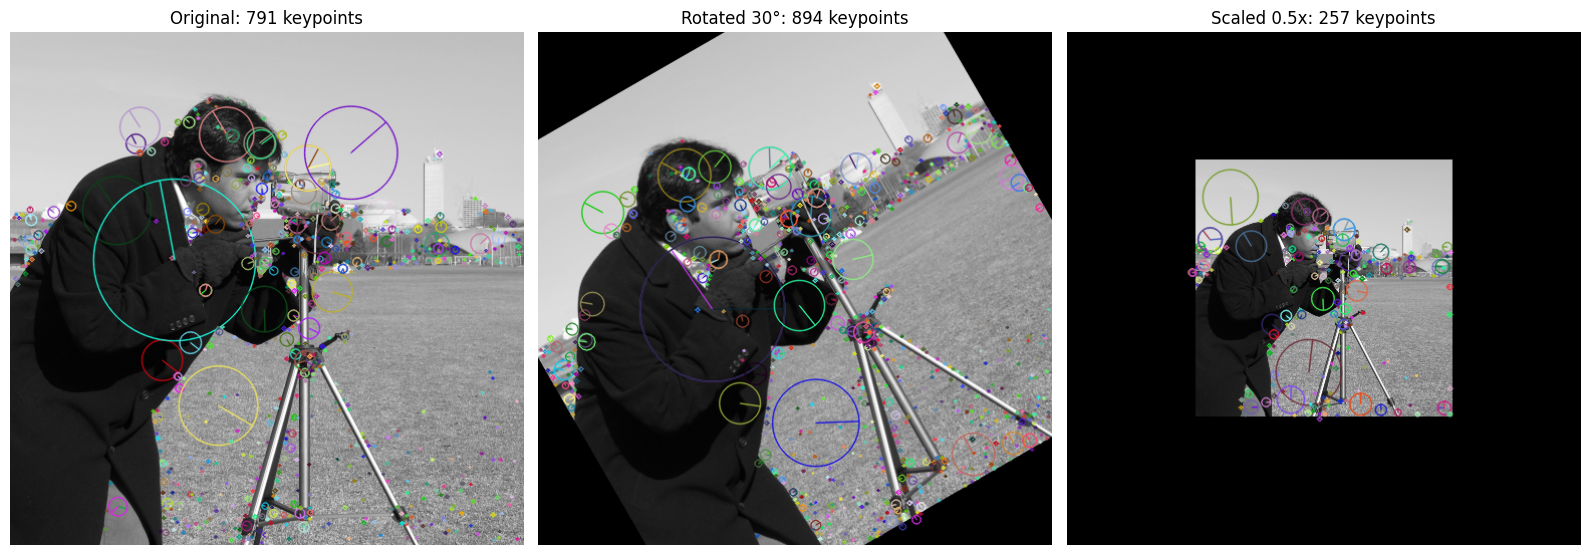

In [4]:
def transform_image(img, angle=0.0, scale=1.0):
    """Rotate/scale about the centre; output canvas size is kept, so some border content is lost."""
    h, w = img.shape
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, scale)
    return cv2.warpAffine(img, M, (w, h)), M

def repeatability(img, angle, scale, tol=3.0):
    sift = cv2.SIFT_create()
    kp1, _ = sift.detectAndCompute(img, None)
    img2, M = transform_image(img, angle, scale)
    kp2, _ = sift.detectAndCompute(img2, None)
    p1 = np.float32([k.pt for k in kp1]).reshape(-1, 1, 2)
    p1_t = cv2.transform(p1, M).reshape(-1, 2)          # where keypoints of image 1 should land
    p2 = np.float32([k.pt for k in kp2])
    h, w = img.shape
    inside = (p1_t[:, 0] >= 0) & (p1_t[:, 0] < w) & (p1_t[:, 1] >= 0) & (p1_t[:, 1] < h)
    d = np.linalg.norm(p1_t[inside][:, None, :] - p2[None, :, :], axis=2).min(axis=1)
    return len(kp1), len(kp2), int(inside.sum()), int((d < tol).sum())

print(f"{'Transform':<22}{'kp(orig)':>9}{'kp(new)':>9}{'visible':>9}{'repeated':>10}{'rate':>8}")
for name, ang, sc in [("Original (0°)", 0, 1.0), ("Rotate 30°", 30, 1.0), ("Rotate 25°", 25, 1.0),
                      ("Scale 0.5x", 0, 0.5), ("Scale 1.5x", 0, 1.5), ("Rotate 30° + scale 0.7x", 30, 0.7)]:
    n1, n2, vis, rep = repeatability(image, ang, sc)
    print(f"{name:<22}{n1:>9}{n2:>9}{vis:>9}{rep:>10}{100 * rep / max(vis, 1):>7.1f}%")

# Visual comparison
fig, ax = plt.subplots(1, 3, figsize=(16, 5.5))
for a, (t, ang, sc) in zip(ax, [("Original", 0, 1.0), ("Rotated 30°", 30, 1.0), ("Scaled 0.5x", 0, 0.5)]):
    im, _ = transform_image(image, ang, sc)
    k, _ = cv2.SIFT_create().detectAndCompute(im, None)
    a.imshow(cv2.drawKeypoints(im, k, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS))
    a.set_title(f"{t}: {len(k)} keypoints"); a.axis("off")
plt.tight_layout(); plt.show()

## 4. SIFT feature matching (Task 5) – Brute-Force matcher + Lowe's ratio test

Keypoints in image 1: 791
Keypoints in image 2: 872
Raw KNN matches     : 791
Good matches (ratio < 0.75): 477


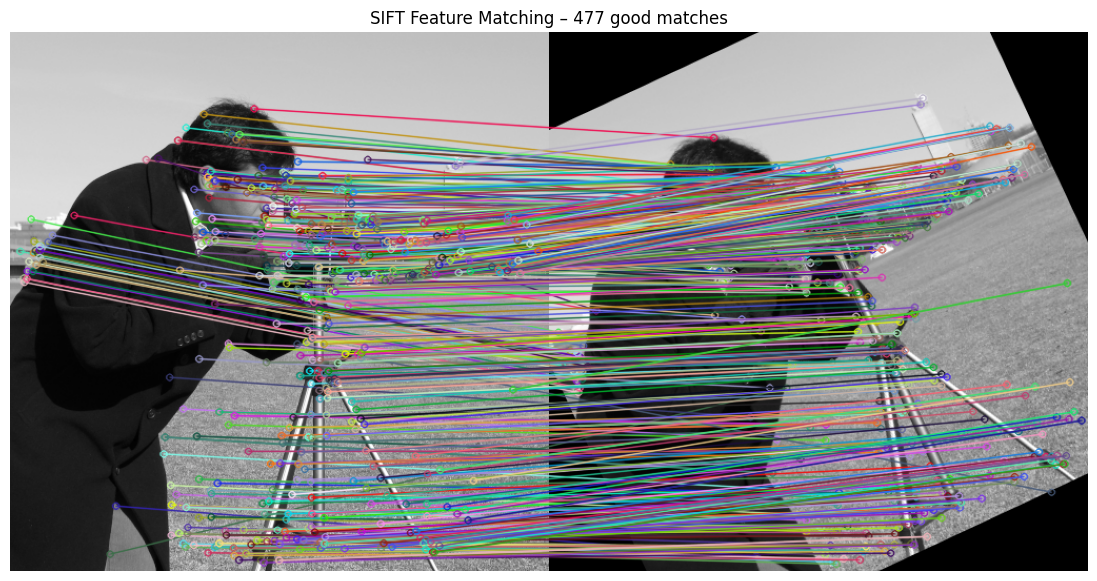

In [5]:
img1 = image
img2, _ = transform_image(img1, 25, 1.0)      # rotated copy (as in the lab sheet)

sift = cv2.SIFT_create()
kp1, des1 = sift.detectAndCompute(img1, None)
kp2, des2 = sift.detectAndCompute(img2, None)

bf = cv2.BFMatcher(cv2.NORM_L2)
matches = bf.knnMatch(des1, des2, k=2)

good_matches = []
for pair in matches:
    if len(pair) == 2 and pair[0].distance < 0.75 * pair[1].distance:   # Lowe's ratio test
        good_matches.append(pair[0])

result = cv2.drawMatches(img1, kp1, img2, kp2, good_matches, None,
                         flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

print("Keypoints in image 1:", len(kp1))
print("Keypoints in image 2:", len(kp2))
print("Raw KNN matches     :", len(matches))
print("Good matches (ratio < 0.75):", len(good_matches))

plt.figure(figsize=(14, 7))
plt.imshow(result)
plt.title(f"SIFT Feature Matching – {len(good_matches)} good matches")
plt.axis("off"); plt.show()

In [6]:
# Check match correctness: a match is correct if image-1 keypoint, after the known rotation, lands near the image-2 keypoint
_, M = transform_image(img1, 25, 1.0)
src = np.float32([kp1[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
dst = np.float32([kp2[m.trainIdx].pt for m in good_matches])
err = np.linalg.norm(cv2.transform(src, M).reshape(-1, 2) - dst, axis=1)
print(f"Correct matches (error < 3 px): {(err < 3).sum()} / {len(good_matches)}  ({100 * (err < 3).mean():.1f}%)")

# Robust geometric verification with RANSAC
H, mask = cv2.findHomography(src, dst, cv2.RANSAC, 3.0)
print("RANSAC inliers:", int(mask.sum()), "/", len(good_matches))

Correct matches (error < 3 px): 461 / 477  (96.6%)
RANSAC inliers: 461 / 477


## 5. Why SIFT beats raw pixel comparison (Task 6)
A raw-pixel patch comparison breaks as soon as the image is rotated, whereas a SIFT descriptor still matches.

Matched point (same physical location): RMS raw-pixel difference = 53.2 grey levels
SIFT distance to its true match        = 87.4
SIFT distance to a typical other point = 505.8   (true match is 5.8x closer)


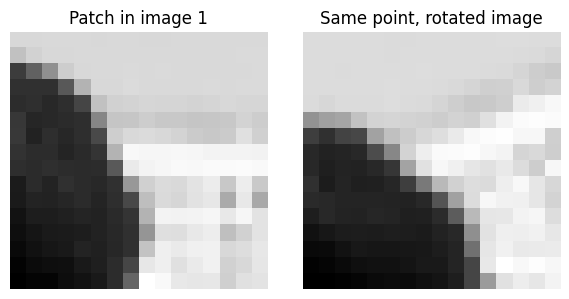

In [7]:
# Take one correctly matched keypoint pair and compare (a) raw 16x16 pixel patches, (b) SIFT descriptors
idx = int(np.argmin(err + (err >= 3) * 1e6))        # best correct match
m = good_matches[idx]
(x1, y1), (x2, y2) = kp1[m.queryIdx].pt, kp2[m.trainIdx].pt

def patch(img, x, y, r=8):
    x, y = int(round(x)), int(round(y))
    return img[y - r:y + r, x - r:x + r].astype(np.float32)

p1, p2 = patch(img1, x1, y1), patch(img2, x2, y2)
pix_dist = np.linalg.norm(p1 - p2) / p1.size ** 0.5            # RMS pixel difference
d_true = np.linalg.norm(des1[m.queryIdx] - des2[m.trainIdx])
d_rand = np.median([np.linalg.norm(des1[m.queryIdx] - des2[j]) for j in range(0, len(des2), max(1, len(des2) // 200))])

print(f"Matched point (same physical location): RMS raw-pixel difference = {pix_dist:.1f} grey levels")
print(f"SIFT distance to its true match        = {d_true:.1f}")
print(f"SIFT distance to a typical other point = {d_rand:.1f}   (true match is {d_rand / d_true:.1f}x closer)")

fig, ax = plt.subplots(1, 2, figsize=(6, 3))
ax[0].imshow(p1, cmap="gray"); ax[0].set_title("Patch in image 1"); ax[0].axis("off")
ax[1].imshow(p2, cmap="gray"); ax[1].set_title("Same point, rotated image"); ax[1].axis("off")
plt.tight_layout(); plt.show()